# Exploratory Data Analysis

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, patterns, and relationships.

In this project, we analyze smartphone usage patterns and their relationship with smartphone addiction.

## Steps for an Exploratory Data Analysis (EDA) Project

### 1. Data Collection

- Collect the smartphone usage dataset.
- Ensure that the dataset is relevant and usable.

### 2. Data Cleaning

- Handle missing values.
- Check for duplicate records.
- Check incorrect or inconsistent data.
- Identify and handle outliers.

### 3. Data Understanding

- Understand the structure of the dataset.
- Review column names and data types.
- Use summary statistics to understand the data.

### 4. Data Analysis

- Analyze individual variables.
- Compare different variables.
- Identify patterns and relationships.

### 5. Data Visualization

- Create bar charts.
- Create histograms.
- Create box plots.
- Create scatter plots.
- Create count plots.
- Create correlation heatmaps.

### 6. Findings and Recommendations

- Summarize the important findings.
- Identify relationships in the data.
- Provide recommendations based on the analysis.

## 1. Data Collection

## Introduction to the Dataset

The dataset contains information about smartphone usage patterns and
smartphone addiction.

It includes information such as age, gender, daily screen time,
social media usage, gaming hours, work or study hours, sleep hours,
notifications, app openings, weekend screen time, stress level,
academic or work impact, and addiction level.

The purpose of this project is to explore smartphone usage patterns,
identify relationships between different variables, and understand
factors associated with smartphone addiction.

In [912]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [913]:

df = pd.read_csv("Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")

#### Display the first 5 rows of the dataset

In [914]:
print(df.head())

  transaction_id user_id  age gender  daily_screen_time_hours  \
0       TXN00001  U00001   21   Male                     3.23   
1       TXN00002  U00002   24  Other                     5.09   
2       TXN00003  U00003   31  Other                     6.06   
3       TXN00004  U00004   32  Other                     7.83   
4       TXN00005  U00005   25   Male                     9.96   

   social_media_hours  gaming_hours  work_study_hours  sleep_hours  \
0                2.01          0.89              4.55         7.55   
1                3.81          2.24              4.44         7.66   
2                1.36          3.83              2.35         4.92   
3                5.85          1.51              3.54         8.23   
4                5.92          3.42              5.27         6.21   

   notifications_per_day  app_opens_per_day  weekend_screen_time stress_level  \
0                    248                154                 3.95       Medium   
1                    127  

#### Display the last 5 rows of the dataset

In [915]:
print(df.tail())

     transaction_id user_id  age  gender  daily_screen_time_hours  \
7495       TXN07496  U07496   26   Other                     9.85   
7496       TXN07497  U07497   35    Male                     5.67   
7497       TXN07498  U07498   22  Female                     9.99   
7498       TXN07499  U07499   23    Male                     8.74   
7499       TXN07500  U07500   27  Female                    10.04   

      social_media_hours  gaming_hours  work_study_hours  sleep_hours  \
7495                1.75          3.13              3.49         5.81   
7496                2.33          2.76              5.90         8.47   
7497                3.61          1.09              1.16         8.17   
7498                1.59          0.07              4.64         6.19   
7499                5.40          0.73              5.45         5.58   

      notifications_per_day  app_opens_per_day  weekend_screen_time  \
7495                    249                122                11.99   
7496

## 2. Data Cleaning

#### Checking Missing Values

In [916]:
# Check whether there are any missing values
print(df.isna().sum())

transaction_id             0
user_id                    0
age                        0
gender                     0
daily_screen_time_hours    0
social_media_hours         0
gaming_hours               0
work_study_hours           0
sleep_hours                0
notifications_per_day      0
app_opens_per_day          0
weekend_screen_time        0
stress_level               0
academic_work_impact       0
addiction_level            0
addicted_label             0
dtype: int64


#### Insight

The dataset contains no missing values. All 7,500 records have complete
values across all 16 columns. Therefore, no missing-value treatment such
as deletion or imputation is required.

#### Checking Duplicate Records

In [917]:
# Check whether there are any duplicate records
print(df.duplicated().sum())

0


#### Insight

The dataset contains no duplicate records. Therefore, no duplicate
rows need to be removed.

#### Checking Data Types

In [918]:
# Check the data type of each column
print(df.dtypes)

transaction_id              object
user_id                     object
age                          int64
gender                      object
daily_screen_time_hours    float64
social_media_hours         float64
gaming_hours               float64
work_study_hours           float64
sleep_hours                float64
notifications_per_day        int64
app_opens_per_day            int64
weekend_screen_time        float64
stress_level                object
academic_work_impact        object
addiction_level             object
addicted_label               int64
dtype: object


#### Insight

The numerical variables are stored in appropriate numerical formats,
while categorical variables such as gender, stress level, and addiction
level are stored as object/string values. No immediate data-type
conversion is required for exploratory analysis.

#### Checking Numerical Values

In [919]:
# Display minimum and maximum values of numerical columns
print(df.describe().T[['min', 'max']])

                           min     max
age                      18.00   35.00
daily_screen_time_hours   3.00   12.00
social_media_hours        0.50    6.00
gaming_hours              0.00    4.00
work_study_hours          0.50    6.00
sleep_hours               4.50    9.00
notifications_per_day    20.00  250.00
app_opens_per_day        15.00  180.00
weekend_screen_time       3.58   14.88
addicted_label            0.00    1.00


#### Insight

The numerical values were checked using their minimum and maximum
values. The age values range from 18 to 35 years, while daily screen
time ranges from 3 to 12 hours. The other smartphone usage variables
also fall within reasonable ranges.

The `addicted_label` contains values from 0 to 1, which is appropriate
for a binary classification label.

No obviously invalid numerical values were identified, so no numerical
values need to be corrected at this stage.

### Checking Categorical Values

In [920]:
print(df['gender'].value_counts())

Male      2553
Other     2486
Female    2461
Name: gender, dtype: int64


In [921]:
print(df['academic_work_impact'].value_counts())

No     3753
Yes    3747
Name: academic_work_impact, dtype: int64


In [922]:
print(df['stress_level'].value_counts())

High      2560
Low       2503
Medium    2437
Name: stress_level, dtype: int64


In [923]:
print(df['addiction_level'].value_counts())

Moderate    2874
Severe      2434
Mild        1373
None         819
Name: addiction_level, dtype: int64


#### Insight

The categorical variables were checked to identify the different
categories and their frequencies.

The gender distribution is relatively balanced, with Male, Female,
and Other categories having similar numbers of records.

The academic/work impact variable is also almost evenly distributed,
with 3,747 records showing an impact and 3,753 records showing no
impact.

The stress level is distributed across three categories: High, Low,
and Medium, with similar numbers of records in each category.

The addiction level consists of four categories: Moderate, Severe,
Mild, and None. Moderate addiction has the highest number of records,
followed by Severe and Mild addiction. The None category contains
819 records.

No obvious inconsistent category names are visible from these
frequency checks.

### Outlier Detection

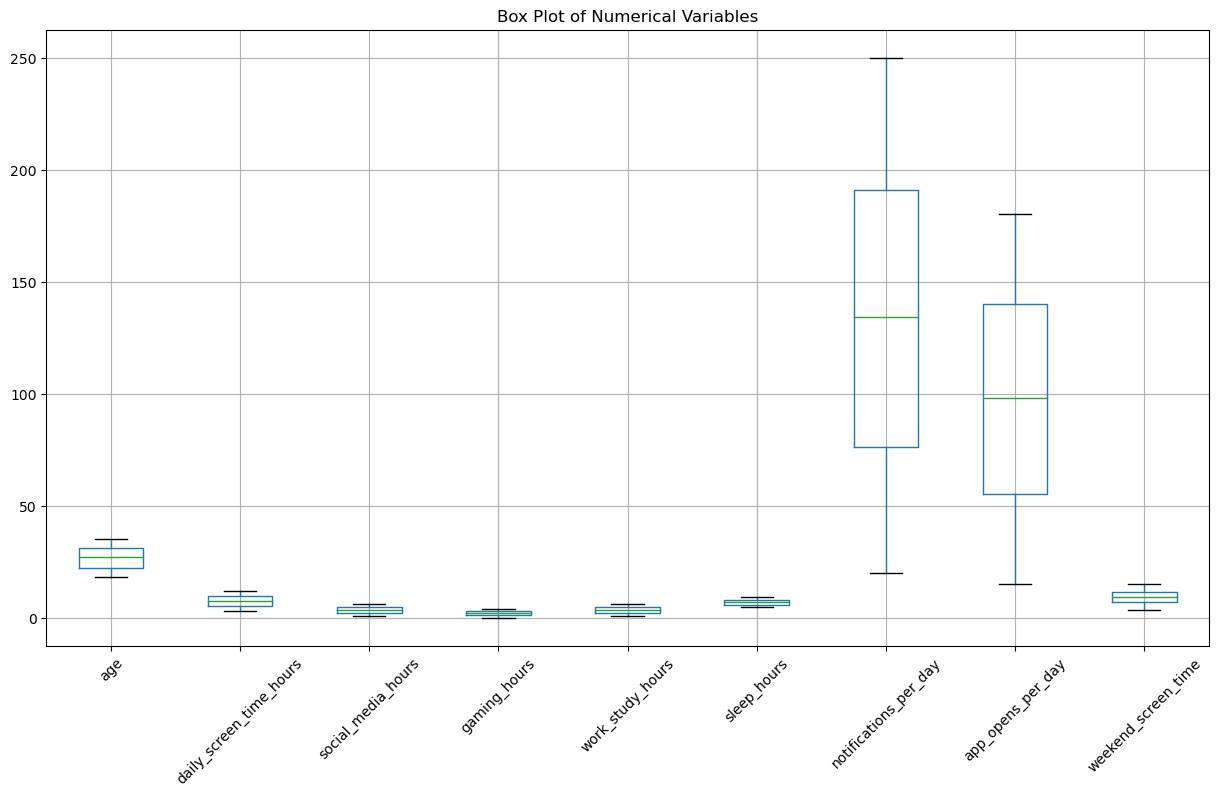

In [924]:
plt.figure(figsize=(15, 8))

outlier_cols = df.select_dtypes(include='number').drop(
    columns=['addicted_label']
)

outlier_cols.boxplot()

plt.xticks(rotation=45)
plt.title('Box Plot of Numerical Variables')
plt.show()

#### Insight

The box plot was used to identify potential outliers in the numerical
variables. No major extreme outliers are observed, so no immediate
outlier removal is required.

## 3. Data Understanding

In [925]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   object 
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   object 
 13  academic_work_impact     7500 non-null   object 
 14  addiction_level         

#### Insight

The dataset contains 7,500 records and 16 columns. All 7,500 records
contain non-null values in every column, confirming that there are no
missing values.

The dataset contains 6 floating-point columns, 4 integer columns, and
6 object-type columns. The numerical columns represent variables such
as age, screen time, social media usage, gaming hours, work/study
hours, sleep hours, notifications, app openings, and weekend screen
time.

The object-type columns contain categorical or identifier information
such as transaction ID, user ID, gender, stress level,
academic/work impact, and addiction level.

Overall, the dataset has a clear structure and is ready for further
exploratory analysis.

### Statistical Summary

The `describe()` function is used to generate descriptive statistics
for the numerical columns in the dataset. It provides information
such as count, mean, standard deviation, minimum, maximum, and
quartile values.

In [926]:
print(df.describe())

               age  daily_screen_time_hours  social_media_hours  gaming_hours  \
count  7500.000000              7500.000000         7500.000000   7500.000000   
mean     26.568800                 7.499912            3.273484      2.014183   
std       5.197108                 2.609188            1.585342      1.146039   
min      18.000000                 3.000000            0.500000      0.000000   
25%      22.000000                 5.220000            1.910000      1.020000   
50%      27.000000                 7.525000            3.270000      2.040000   
75%      31.000000                 9.810000            4.630000      2.990000   
max      35.000000                12.000000            6.000000      4.000000   

       work_study_hours  sleep_hours  notifications_per_day  \
count       7500.000000  7500.000000            7500.000000   
mean           3.242420     6.737561             134.257333   
std            1.600765     1.283605              66.586883   
min            0.5

#### Insight

The descriptive statistics provide an overview of the numerical
variables in the smartphone usage dataset.

The average age of the users is approximately 26.57 years. The average
daily screen time is approximately 7.50 hours, while the average
social media usage is approximately 3.27 hours and average gaming time
is approximately 2.01 hours.

Users spend an average of approximately 3.24 hours on work or study
and sleep for approximately 6.74 hours per day. The average number of
notifications is approximately 134 per day, and users open applications
approximately 98 times per day on average.

The average weekend screen time is approximately 9.24 hours.


## 4. Data Analysis

### Questions for Analysis

### 1. What is the distribution of users by gender?

Male      2553
Other     2486
Female    2461
Name: gender, dtype: int64


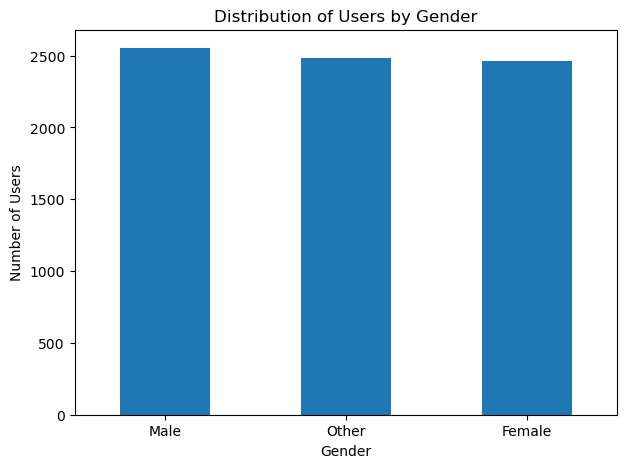

In [927]:
gender_count = df['gender'].value_counts()

print(gender_count)
gender_count.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Distribution of Users by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.show()

#### Insight

The gender distribution is relatively balanced, with 2,553 Male,
2,486 Other, and 2,461 Female users. Male users form the largest
group, while Female users form the smallest group.

### 2. What is the distribution of users across different addiction levels?

Moderate    2874
Severe      2434
Mild        1373
None         819
Name: addiction_level, dtype: int64


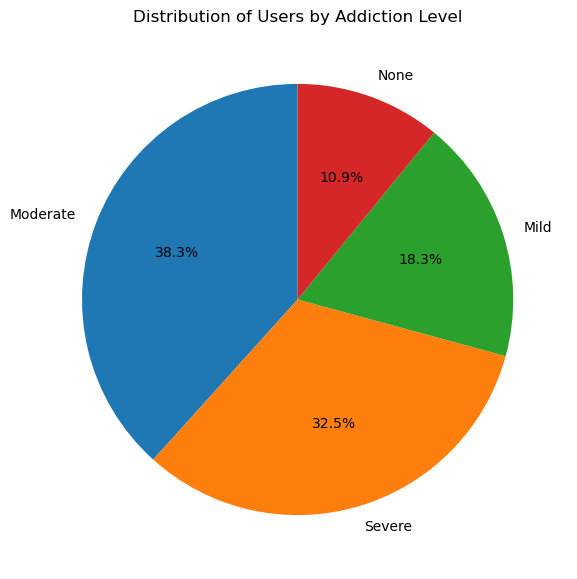

In [928]:
addiction_counts = df['addiction_level'].value_counts()

print(addiction_counts)

plt.figure(figsize=(7,7))

plt.pie(
    addiction_counts,
    labels=addiction_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Users by Addiction Level')
plt.show()

#### Insight

The pie chart shows that Moderate addiction represents the largest
proportion of users at 38.3%, followed by Severe addiction at 32.5%.
Mild addiction accounts for 18.3%, while None addiction represents
10.9% of users.

### 3. What is the average daily screen time among users?

In [929]:
average_screen_time = df['daily_screen_time_hours'].mean()

print("Average daily screen time:", average_screen_time)


Average daily screen time: 7.499911999999999


#### Insight

The average daily screen time among users is approximately 7.50 hours.

### 4. How does daily screen time vary across different addiction levels?

addiction_level
Mild        5.535062
Moderate    8.351427
None        4.522833
Severe      8.604560
Name: daily_screen_time_hours, dtype: float64


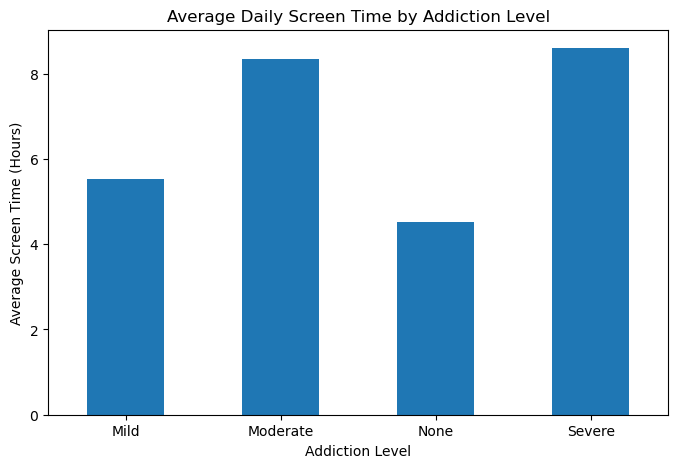

In [930]:
screen_time_by_addiction = df.groupby(
    'addiction_level'
)['daily_screen_time_hours'].mean()

print(screen_time_by_addiction)
screen_time_by_addiction.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Daily Screen Time by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Average Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Users with Severe and Moderate addiction levels have higher average
daily screen time at approximately 8.60 and 8.35 hours respectively,
while users with None addiction have the lowest average at approximately
4.52 hours.

### 5. How does social media usage vary across different addiction levels?

addiction_level
Mild        2.258128
Moderate    3.579694
None        2.240696
Severe      3.832190
Name: social_media_hours, dtype: float64


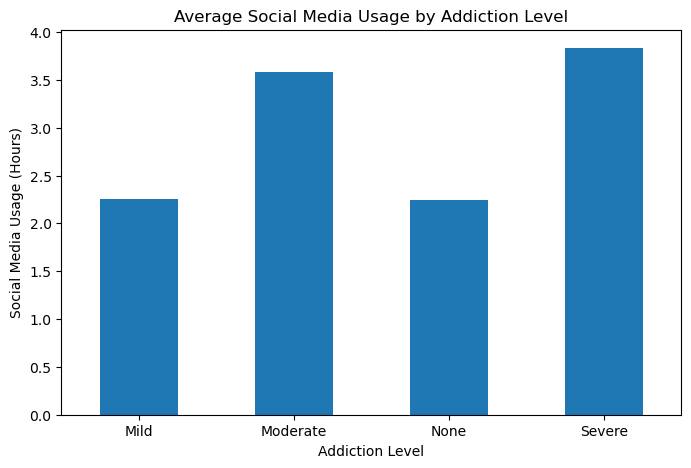

In [931]:
social_media_by_addiction = df.groupby(
    'addiction_level'
)['social_media_hours'].mean()

print(social_media_by_addiction)
social_media_by_addiction.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Social Media Usage by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Social Media Usage (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Social media usage varies across addiction levels, with higher average
social media usage generally observed among users with higher addiction
levels.

### Q6. How many users have more than 8 hours of daily screen time?

In [932]:
high_screen_time = df[
    df['daily_screen_time_hours'] > 8
]

print(
    'Users with more than 8 hours of daily screen time:',
    len(high_screen_time)
)

Users with more than 8 hours of daily screen time: 3344


#### Insight

The condition identifies users whose daily screen time exceeds 8 hours.
This helps identify users with relatively high smartphone usage.

### Q7. How many users have more than 8 hours of screen time and less than 6 hours of sleep?

In [933]:
high_screen_low_sleep = df[
    (df['daily_screen_time_hours'] > 8) &
    (df['sleep_hours'] < 6)
]

print(
    'Users with more than 8 hours screen time and less than 6 hours sleep:',
    len(high_screen_low_sleep)
)

Users with more than 8 hours screen time and less than 6 hours sleep: 1064


#### Insight

This condition identifies users who have both high daily screen time and
relatively low sleep duration. It helps identify a group with potentially
unbalanced smartphone usage and sleep patterns.

### 8. How does stress level relate to smartphone addiction?

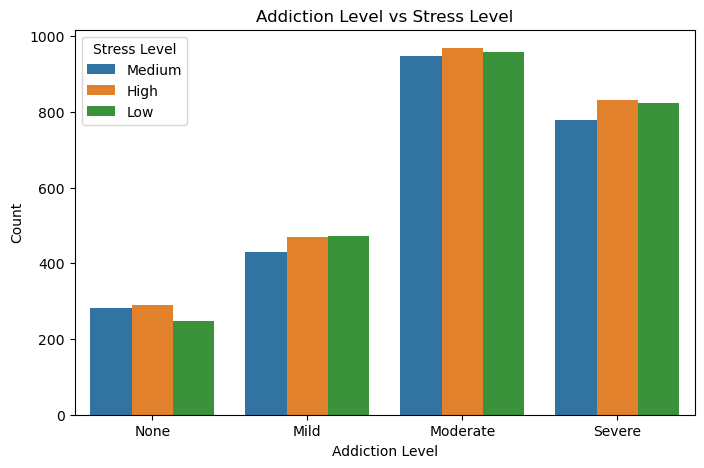

In [961]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='addiction_level',
    hue='stress_level'
)

plt.title('Addiction Level vs Stress Level')
plt.xlabel('Addiction Level')
plt.ylabel('Count')
plt.legend(title='Stress Level')
plt.show()

#### Insight

Moderate and Severe addiction levels have higher user counts across all
stress levels compared with Mild and None addiction levels. The
stress-level counts within each addiction level are relatively similar.

### 9. How does academic or work impact vary across different addiction levels?

addiction_level       Mild  Moderate  None  Severe
academic_work_impact                              
No                     690      1412   407    1244
Yes                    683      1462   412    1190


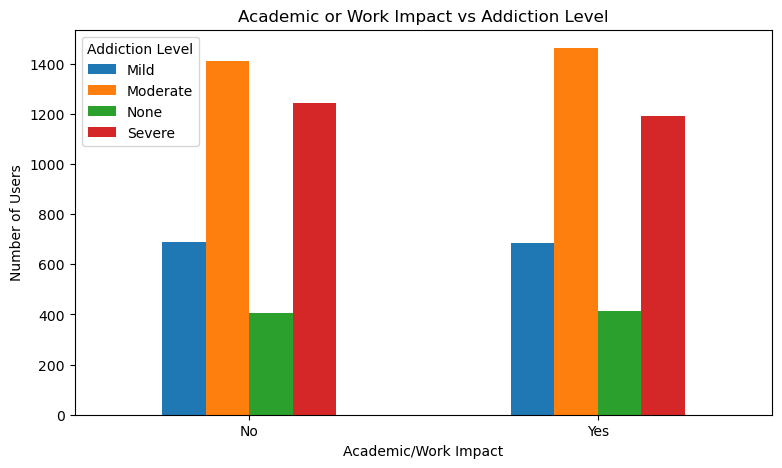

In [935]:
impact_addiction = pd.crosstab(
    df['academic_work_impact'],
    df['addiction_level']
)

print(impact_addiction)
impact_addiction.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Academic or Work Impact vs Addiction Level')
plt.xlabel('Academic/Work Impact')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.legend(title='Addiction Level')
plt.show()

#### Insight

Academic/work impact is present across all addiction levels. Moderate
addiction has the highest number of users in both impact categories,
while None addiction has the lowest. The number of users reporting
academic/work impact is slightly higher for Moderate addiction, while
the Severe category has slightly more users without reported impact.

### 10. Which age group has the highest average daily screen time?

In [936]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 20, 25, 30, 35],
    labels=['18-20', '21-25', '26-30', '31-35']
)

age_screen_time = df.groupby(
    'age_group',
    observed=True
)['daily_screen_time_hours'].mean()

print(age_screen_time)


age_group
18-20    7.405383
21-25    7.490810
26-30    7.509763
31-35    7.553316
Name: daily_screen_time_hours, dtype: float64


#### Insight

The 31–35 age group has the highest average daily screen time at
approximately 7.55 hours, while the 18–20 age group has the lowest
average at approximately 7.41 hours.

### 11. Is there a relationship between daily screen time and sleep hours?

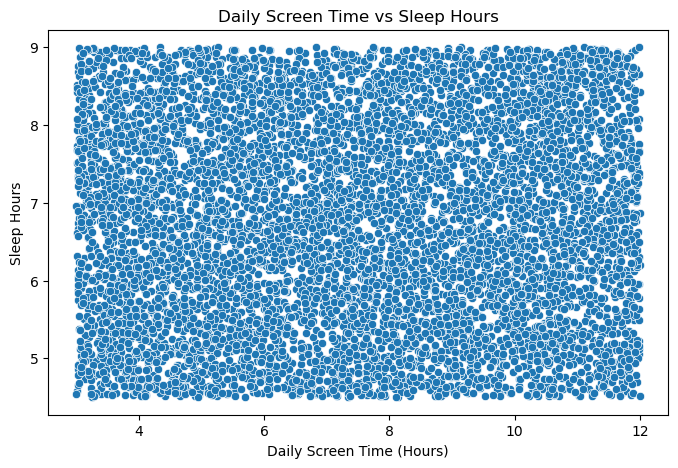

Correlation: 0.019343


In [937]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='daily_screen_time_hours',
    y='sleep_hours'
)

plt.title('Daily Screen Time vs Sleep Hours')
plt.xlabel('Daily Screen Time (Hours)')
plt.ylabel('Sleep Hours')
plt.show()

correlation = df[
    'daily_screen_time_hours'
].corr(
    df['sleep_hours']
)

print('Correlation:', round(correlation, 6))

#### Insight

The correlation coefficient between daily screen time and sleep hours
is 0.019343. This indicates a very weak positive relationship.
Therefore, daily screen time and sleep hours have almost no linear
relationship in this dataset.

### 12. Is there a relationship between daily screen time and app openings per day?

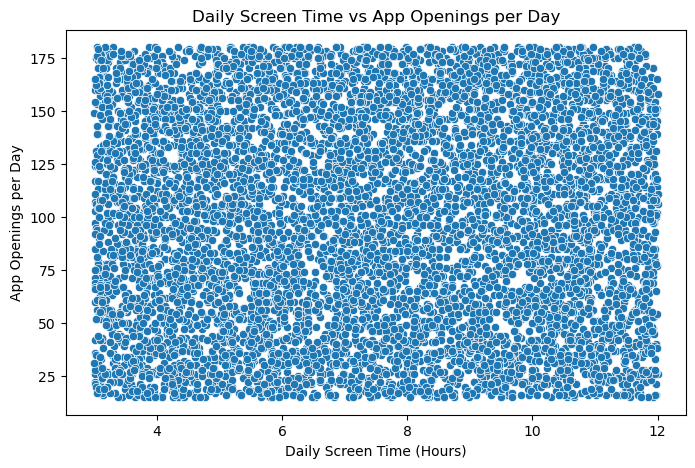

Correlation: 0.024448


In [938]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='daily_screen_time_hours',
    y='app_opens_per_day'
)

plt.title('Daily Screen Time vs App Openings per Day')
plt.xlabel('Daily Screen Time (Hours)')
plt.ylabel('App Openings per Day')
plt.show()

correlation = df[
    'daily_screen_time_hours'
].corr(
    df['app_opens_per_day']
)

print('Correlation:', round(correlation, 6))

#### Insight

The correlation coefficient between daily screen time and app openings
per day is 0.024448. This indicates a very weak positive relationship.
Therefore, daily screen time and app openings have almost no linear
relationship in this dataset.

### Q13. Is there a relationship between daily screen time and notifications per day?

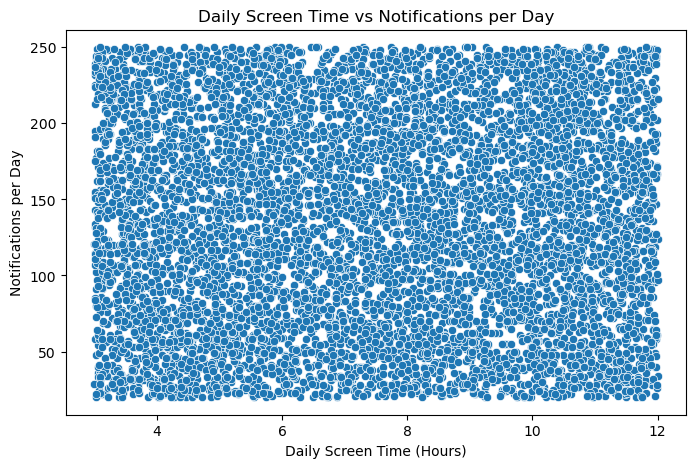

Correlation: 0.000811


In [939]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='daily_screen_time_hours',
    y='notifications_per_day'
)

plt.title('Daily Screen Time vs Notifications per Day')
plt.xlabel('Daily Screen Time (Hours)')
plt.ylabel('Notifications per Day')
plt.show()

correlation = df[
    'daily_screen_time_hours'
].corr(
    df['notifications_per_day']
)

print('Correlation:', round(correlation, 6))

#### Insight

The correlation coefficient between daily screen time and notifications
per day is approximately 0.000811. This indicates almost no linear
relationship between the two variables in this dataset.

### 14. How does weekend screen time compare with daily screen time?

daily_screen_time_hours    7.499912
weekend_screen_time        9.243827
dtype: float64


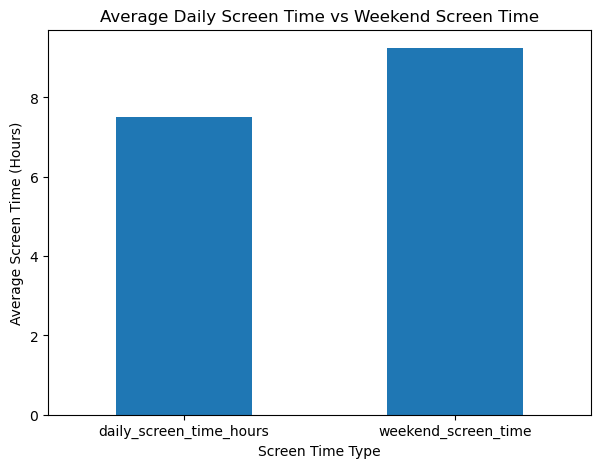

In [940]:
average_screen_time = df[
    ['daily_screen_time_hours', 'weekend_screen_time']
].mean()

print(average_screen_time)
average_screen_time.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Daily Screen Time vs Weekend Screen Time')
plt.xlabel('Screen Time Type')
plt.ylabel('Average Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

The average weekend screen time is approximately 9.24 hours, which is
higher than the average daily screen time of approximately 7.50 hours.
This indicates that smartphone usage is higher on weekends in this
dataset.

### 15. Is there a relationship between smartphone usage and addiction status?

addicted_label
0    5.156861
1    8.467502
Name: daily_screen_time_hours, dtype: float64


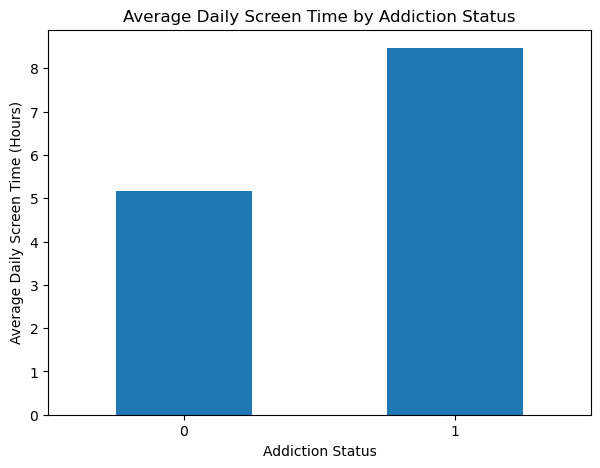

In [941]:
usage_by_status = df.groupby(
    'addicted_label'
)['daily_screen_time_hours'].mean()

print(usage_by_status)
usage_by_status.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Daily Screen Time by Addiction Status')
plt.xlabel('Addiction Status')
plt.ylabel('Average Daily Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Users in addiction status category 1 have a higher average daily screen
time of approximately 8.47 hours, compared with approximately 5.16 hours
for category 0.

### Q16. How does average work/study time vary across different addiction levels?


addiction_level
Mild        3.227822
Moderate    3.240438
None        3.259536
Severe      3.247235
Name: work_study_hours, dtype: float64


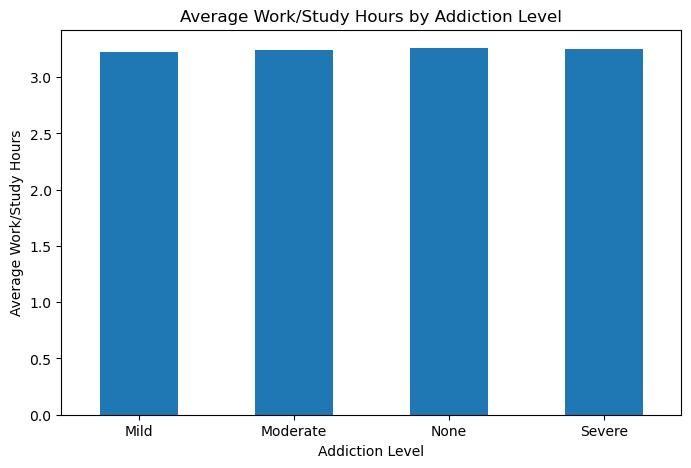

In [942]:
work_study_by_addiction = df.groupby(
    'addiction_level'
)['work_study_hours'].mean()

print(work_study_by_addiction)

work_study_by_addiction.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Work/Study Hours by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Average Work/Study Hours')
plt.xticks(rotation=0)
plt.show()


#### Insight

Average work/study hours are very similar across all addiction levels,
ranging from approximately 3.23 to 3.26 hours per day. Therefore,
work/study time shows very little variation across the addiction
categories in this dataset.

### Q17. How many users have more than 5 hours of social media usage and Severe addiction?

In [943]:
high_social_severe = df[
    (df['social_media_hours'] > 5) &
    (df['addiction_level'] == 'Severe')
]

print(
    'Users with more than 5 hours social media usage and Severe addiction:',
    len(high_social_severe)
)

Users with more than 5 hours social media usage and Severe addiction: 700


#### Insight

This condition identifies users who have high social media usage and
belong to the Severe addiction category. It provides a focused view of
users with both high social media usage and severe addiction.

### Q18. How many users have more than 10 hours of weekend screen time?


In [944]:
high_weekend_usage = df[
    df['weekend_screen_time'] > 10
]

print(
    'Users with more than 10 hours of weekend screen time:',
    len(high_weekend_usage)
)

Users with more than 10 hours of weekend screen time: 3130


#### Insight

The condition identifies users whose weekend screen time exceeds
10 hours. This helps identify users with particularly high smartphone
usage during weekends.

### Q19. How does weekend screen time vary across different addiction levels?


addiction_level
Mild         7.292251
Moderate    10.090647
None         6.227790
Severe      10.359638
Name: weekend_screen_time, dtype: float64


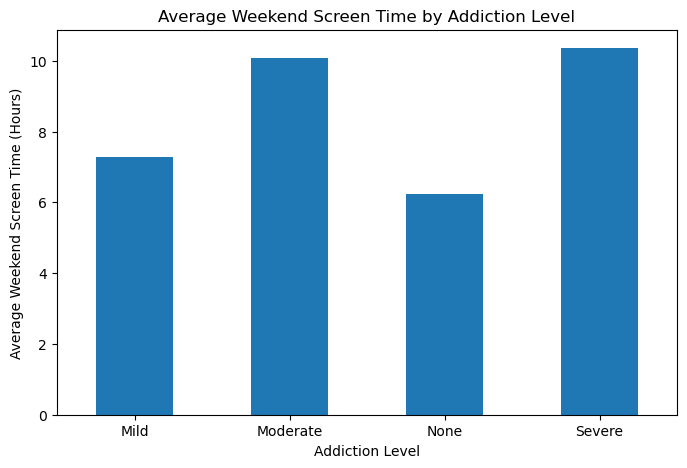

In [945]:
weekend_by_addiction = df.groupby(
    'addiction_level'
)['weekend_screen_time'].mean()

print(weekend_by_addiction)

weekend_by_addiction.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Weekend Screen Time by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Average Weekend Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Average weekend screen time increases across the addiction levels.
Users with Severe and Moderate addiction have the highest average
weekend screen time at approximately 10.36 and 10.09 hours respectively,
while users with None addiction have the lowest average at approximately
6.23 hours.

### Q20. How does average screen time vary across different stress levels?


stress_level
High      7.581359
Low       7.498761
Medium    7.415535
Name: daily_screen_time_hours, dtype: float64


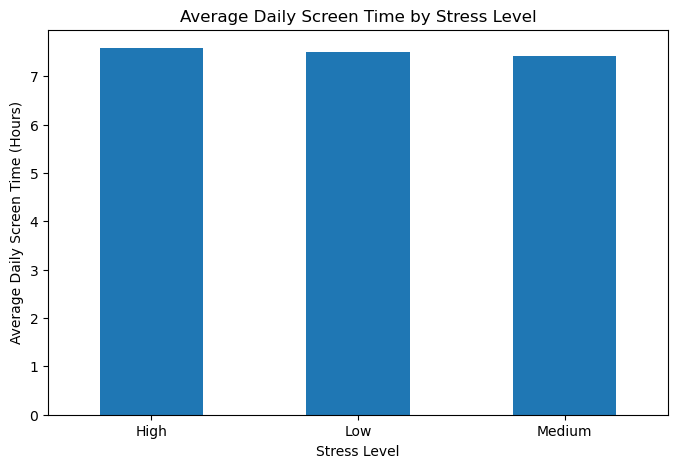

In [946]:
screen_time_by_stress = df.groupby(
    'stress_level'
)['daily_screen_time_hours'].mean()

print(screen_time_by_stress)

screen_time_by_stress.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Daily Screen Time by Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Average Daily Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Users with High stress have the highest average daily screen time at
approximately 7.58 hours, followed by Low stress at 7.50 hours and
Medium stress at 7.42 hours. The differences are relatively small across
the stress levels.

### Q21. What is the distribution of academic/work impact among users?


No     3753
Yes    3747
Name: academic_work_impact, dtype: int64


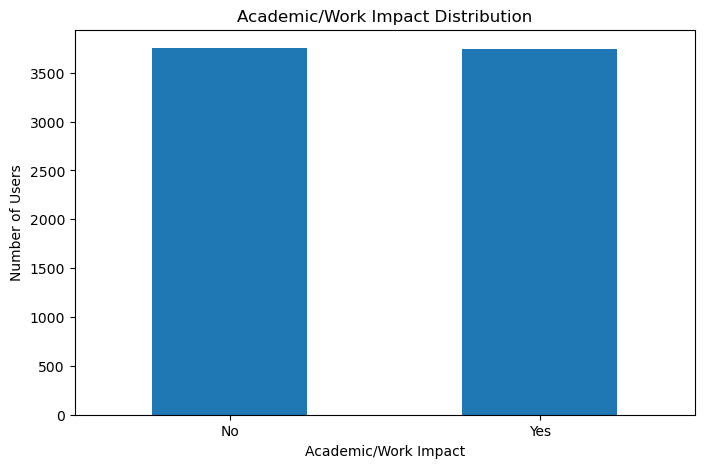

In [947]:
academic_impact_counts = df['academic_work_impact'].value_counts()

print(academic_impact_counts)

academic_impact_counts.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Academic/Work Impact Distribution')
plt.xlabel('Academic/Work Impact')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.show()


#### Insight

The distribution of academic/work impact is almost evenly balanced.
A total of 3,753 users reported No impact, while 3,747 users reported
Yes impact. Therefore, both categories are nearly equally represented
in the dataset.

### Q22. How does academic/work impact vary across different addiction levels?


academic_work_impact    No   Yes
addiction_level                 
Mild                   690   683
Moderate              1412  1462
None                   407   412
Severe                1244  1190


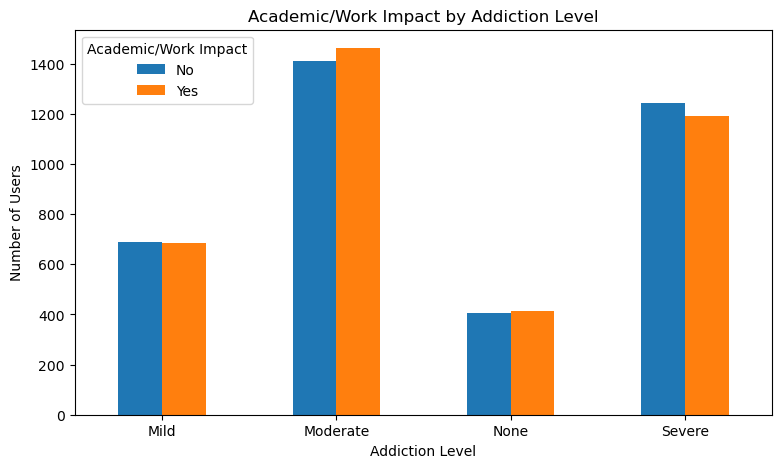

In [948]:
impact_by_addiction = pd.crosstab(
    df['addiction_level'],
    df['academic_work_impact']
)

print(impact_by_addiction)

impact_by_addiction.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Academic/Work Impact by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.legend(title='Academic/Work Impact')
plt.show()

#### Insight

Academic/work impact is distributed across all addiction levels.
Moderate addiction has the highest number of users in both impact
categories, while None addiction has the lowest. The counts of users
reporting Yes and No impact are relatively similar within each
addiction level.

### Q23. Which gender has the highest average daily screen time?

gender
Female    7.446233
Male      7.560027
Other     7.491315
Name: daily_screen_time_hours, dtype: float64


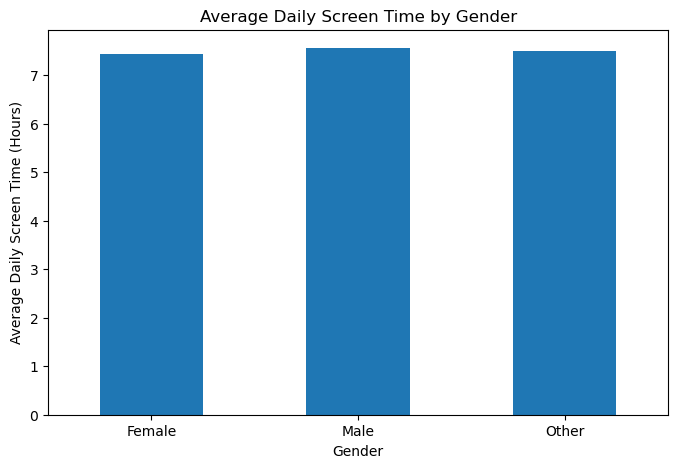

In [949]:
screen_time_by_gender = df.groupby(
    'gender'
)['daily_screen_time_hours'].mean()

print(screen_time_by_gender)

screen_time_by_gender.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Daily Screen Time by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Daily Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Male users have the highest average daily screen time at approximately
7.56 hours, followed by Other at 7.49 hours and Female at 7.45 hours.
The differences between the gender categories are small.

### Q24. How does addiction level vary across different age groups?


addiction_level  Mild  Moderate  None  Severe
age_group                                    
18-20             235       484   144     376
21-25             372       801   215     648
26-30             356       793   233     684
31-35             410       796   227     726


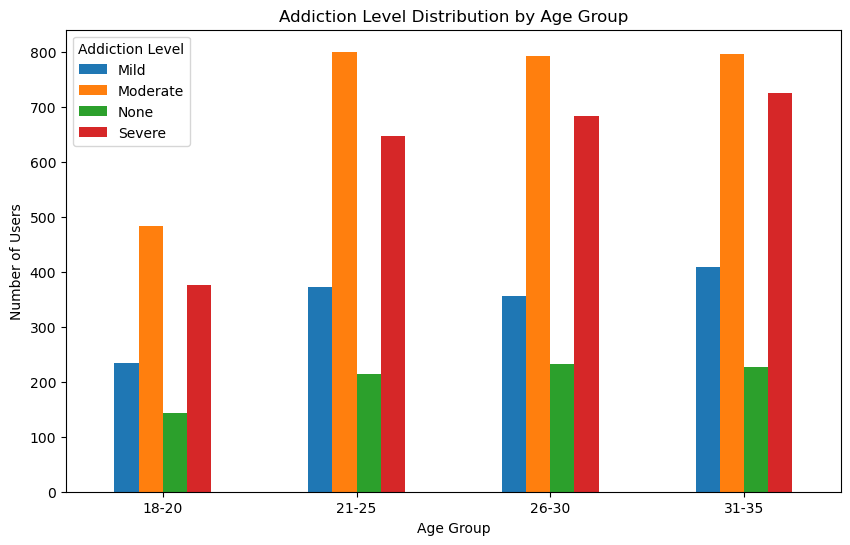

In [950]:
age_addiction = pd.crosstab(
    df['age_group'],
    df['addiction_level']
)

print(age_addiction)

age_addiction.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Addiction Level Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Users')
plt.xticks(rotation=0)
plt.legend(title='Addiction Level')
plt.show()

Moderate addiction has the highest number of users in each age group.
The 31–35 age group has the highest number of Mild addiction users,
while the 21–25 age group has the highest number of Moderate addiction
users. Overall, Moderate and Severe addiction categories have higher
counts across all age groups.

### Q25. How does weekend screen time vary between users with and without academic or work impact?


academic_work_impact
No     9.258039
Yes    9.229592
Name: weekend_screen_time, dtype: float64


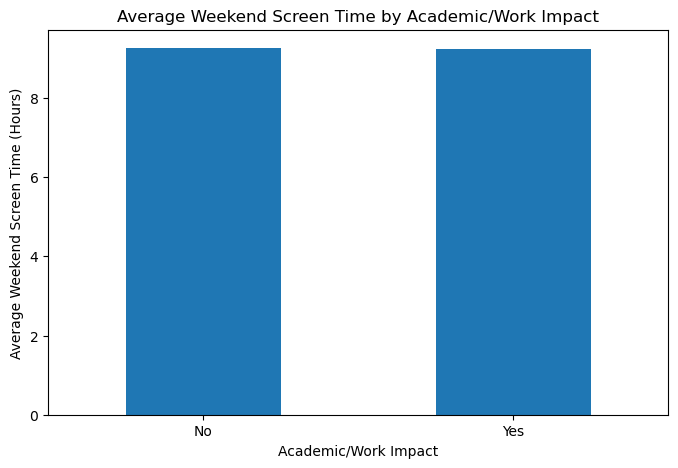

In [951]:
weekend_by_impact = df.groupby(
    'academic_work_impact'
)['weekend_screen_time'].mean()

print(weekend_by_impact)

weekend_by_impact.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Average Weekend Screen Time by Academic/Work Impact')
plt.xlabel('Academic/Work Impact')
plt.ylabel('Average Weekend Screen Time (Hours)')
plt.xticks(rotation=0)
plt.show()

#### Insight

Users who reported No academic or work impact have an average weekend
screen time of approximately 9.26 hours, while users who reported Yes
have an average of approximately 9.23 hours. The difference is very
small, indicating that weekend screen time is nearly similar between the
two groups.

### Feature Engineering

Feature engineering is the process of creating new features from
existing data to obtain additional insights into smartphone usage
patterns.

In [952]:
df['total_entertainment_hours'] = (
    df['social_media_hours'] + df['gaming_hours']
)

df['weekend_screen_difference'] = (
    df['weekend_screen_time'] - df['daily_screen_time_hours']
)

df['screen_time_per_sleep_hour'] = (
    df['daily_screen_time_hours'] / df['sleep_hours']
)

print(df[[
    'total_entertainment_hours',
    'weekend_screen_difference',
    'screen_time_per_sleep_hour'
]].head())

   total_entertainment_hours  weekend_screen_difference  \
0                       2.90                       0.72   
1                       6.05                       1.62   
2                       5.19                       2.62   
3                       7.36                       1.94   
4                       9.34                       2.59   

   screen_time_per_sleep_hour  
0                    0.427815  
1                    0.664491  
2                    1.231707  
3                    0.951397  
4                    1.603865  


#### Feature Analysis

The newly created features provide additional information about
entertainment usage, weekend screen-time differences, and screen time
relative to sleep duration.

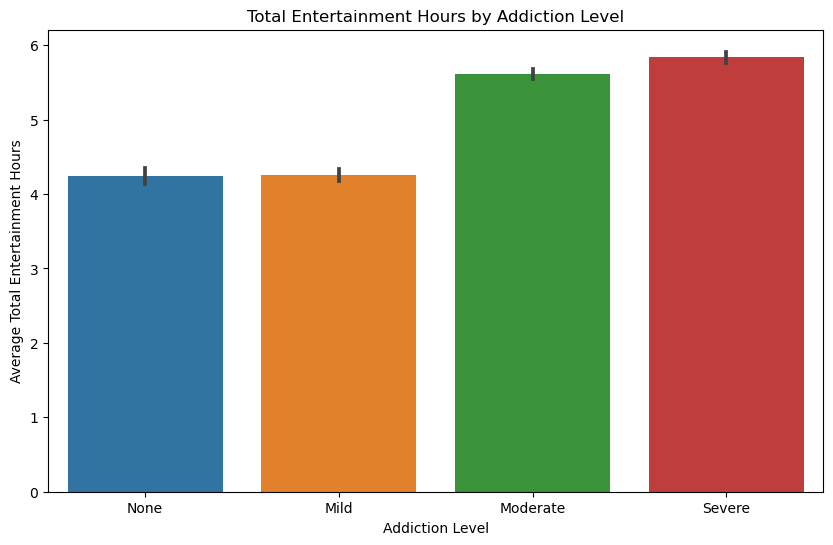

In [953]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='addiction_level',
    y='total_entertainment_hours'
)

plt.title('Total Entertainment Hours by Addiction Level')
plt.xlabel('Addiction Level')
plt.ylabel('Average Total Entertainment Hours')
plt.show()

#### Insight

Average total entertainment hours vary across addiction levels, with
higher entertainment time generally observed among users with higher
addiction levels. This shows how the engineered feature can be used to
compare entertainment-related smartphone usage across different
addiction levels.

## 5. Data Visualization

### Correlation Heatmap

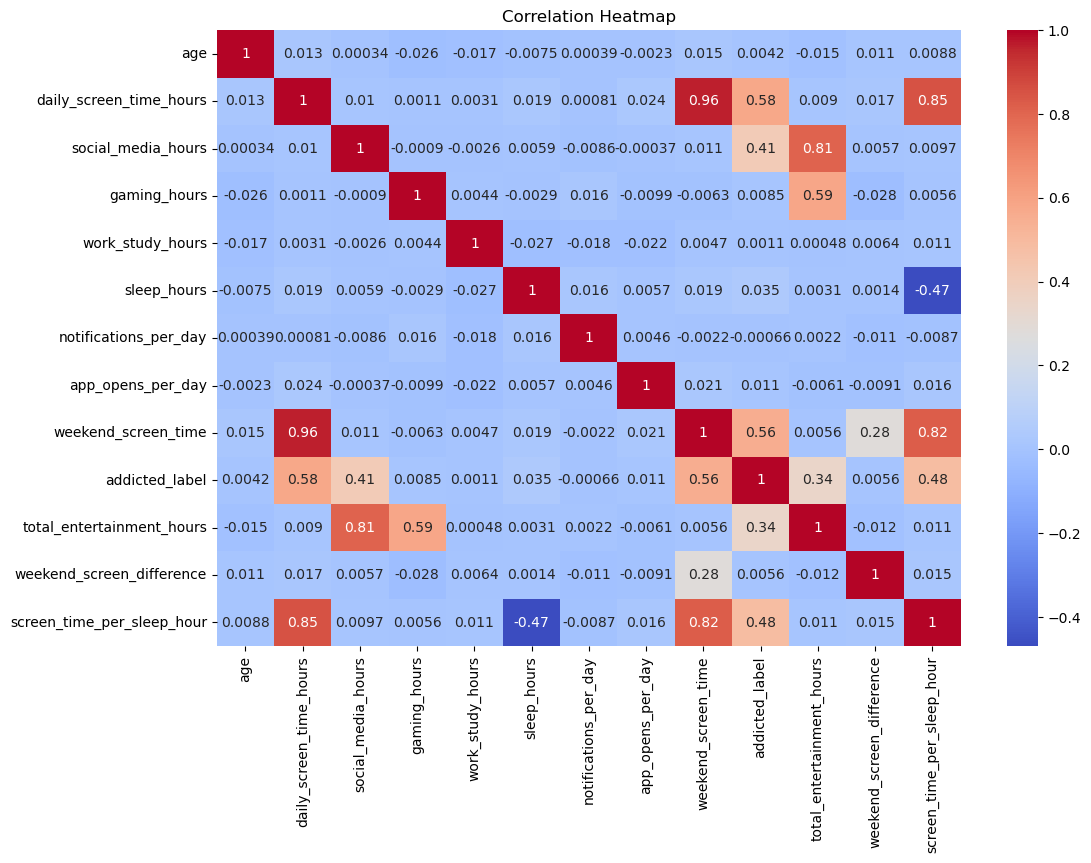

In [954]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

#### Insight

The correlation heatmap shows that daily screen time and weekend screen
time have a very strong positive relationship. Daily screen time also
shows a moderate positive relationship with addicted label, while social
media usage has a moderate positive relationship with addicted label.
These correlations indicate associations between the variables and do
not necessarily imply causation.

### Pie Chart - Addiction Level Distribution

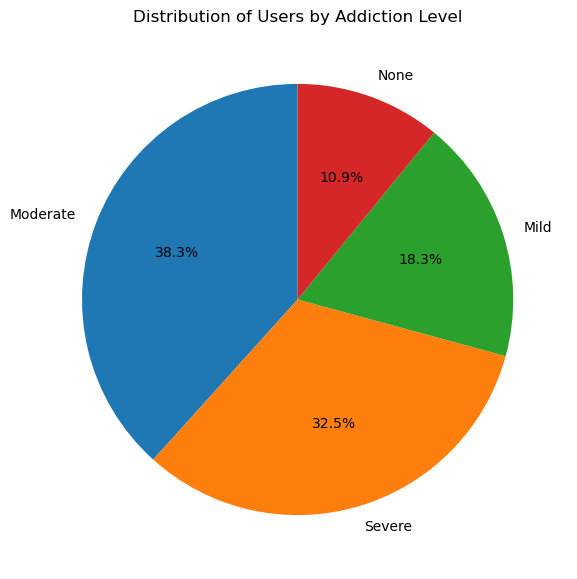

In [955]:
addiction_counts = df['addiction_level'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    addiction_counts,
    labels=addiction_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Users by Addiction Level')
plt.show()

#### Insight

The pie chart shows the distribution of users across the four addiction
levels. Moderate addiction represents the largest proportion at 38.3%,
followed by Severe addiction at 32.5%. Mild addiction accounts for
18.3%, while None addiction represents the smallest proportion at 10.9%.

### Distribution Graphs (Histograms)

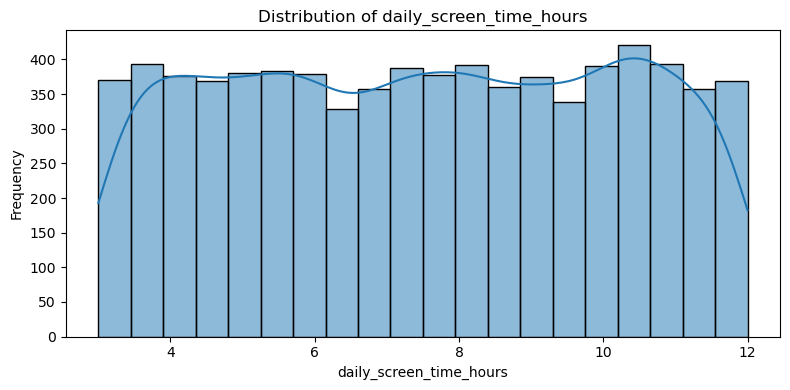

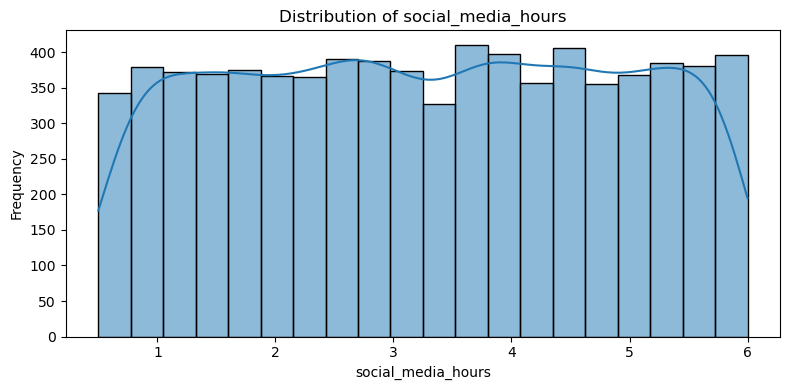

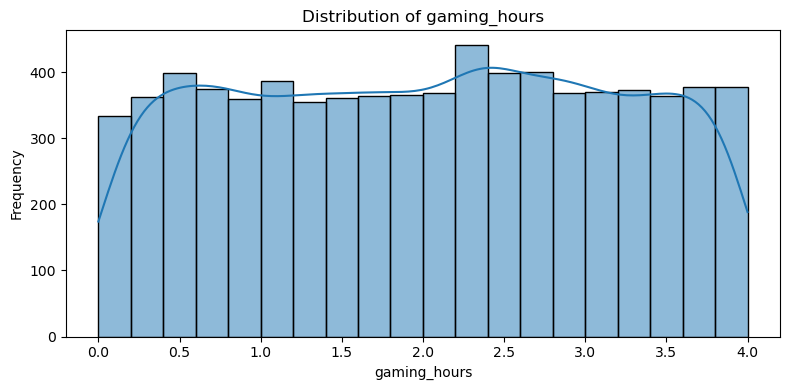

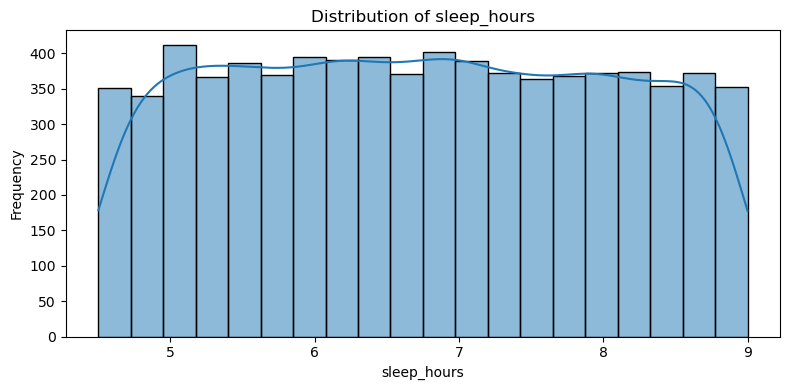

In [956]:
distribution_cols = [
    'daily_screen_time_hours',
    'social_media_hours',
    'gaming_hours',
    'sleep_hours'
]

for col in distribution_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        bins=20,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

#### Insight

The distribution graphs show how daily screen time, social media usage,
gaming time, and sleep hours are spread across the users. These graphs
help to understand the overall distribution of important smartphone
usage variables.

### Count Plot

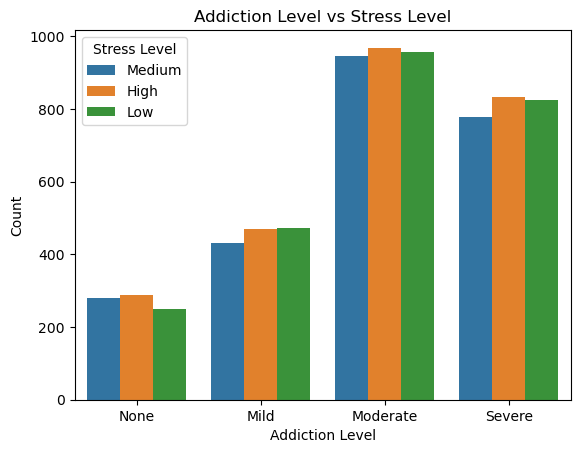

In [957]:
sns.countplot(
    data=df,
    x='addiction_level',
    hue='stress_level'
)

plt.title('Addiction Level vs Stress Level')
plt.xlabel('Addiction Level')
plt.ylabel('Count')
plt.legend(title='Stress Level')
plt.show()

#### Insight

The count plot shows that Moderate and Severe addiction levels have
higher user counts across all stress levels compared with Mild and None
addiction levels. The stress-level counts within each addiction level
are relatively similar.

### Grouped Bar Plot

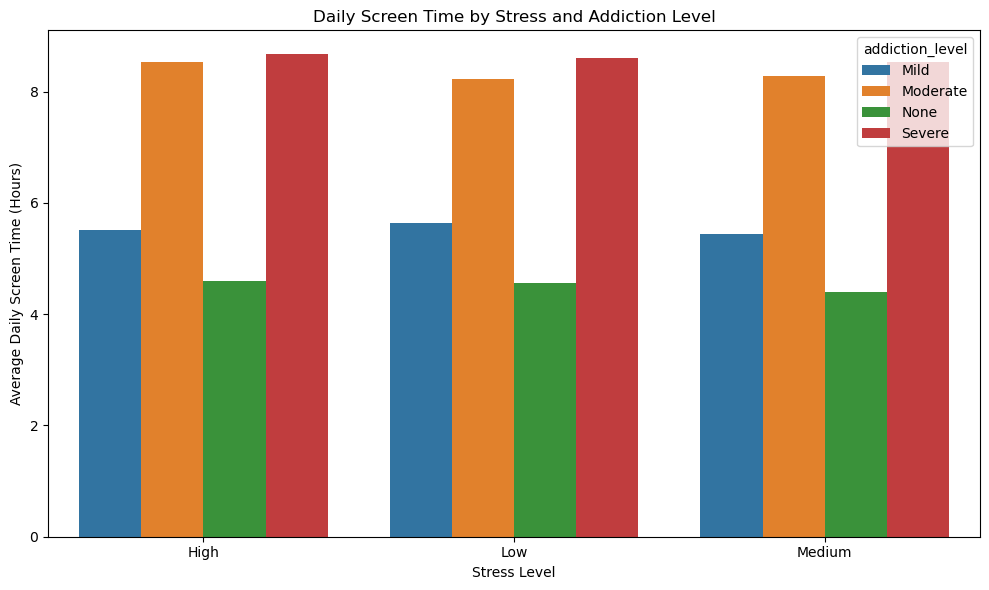

In [958]:
group_plot = df.groupby(
    ['stress_level', 'addiction_level']
)['daily_screen_time_hours'].mean().reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=group_plot,
    x='stress_level',
    y='daily_screen_time_hours',
    hue='addiction_level'
)

plt.title('Daily Screen Time by Stress and Addiction Level')
plt.xlabel('Stress Level')
plt.ylabel('Average Daily Screen Time (Hours)')
plt.tight_layout()
plt.show()

#### Insight

Severe and Moderate addiction levels show higher average daily screen
time across all stress levels, while users with None addiction have the
lowest average screen time. The differences across stress levels are
relatively small.

### Scatter Plot - Social Media Usage vs Daily Screen Time

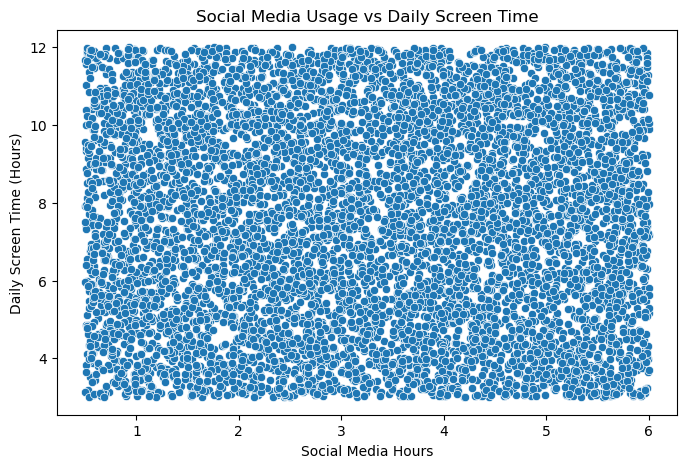

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='social_media_hours',
    y='daily_screen_time_hours'
)

plt.title('Social Media Usage vs Daily Screen Time')
plt.xlabel('Social Media Hours')
plt.ylabel('Daily Screen Time (Hours)')
plt.show()

#### Insight

The scatter plot shows the relationship between social media usage and
daily screen time. The points are widely distributed, indicating that
social media usage does not show a strong linear relationship with daily
screen time in this dataset.

## 6. Findings and Recommendations

### Suggestions & Recommendations

- Encourage users to maintain a balanced daily screen time.
- Limit unnecessary social media and gaming usage.
- Reduce excessive notifications and frequent app openings.
- Maintain sufficient sleep while managing smartphone usage.
- Monitor screen-time patterns regularly to identify unhealthy usage habits.

### Conclusion

The exploratory analysis shows that smartphone usage patterns differ
across users and are associated with different addiction levels.
Monitoring screen time, entertainment usage, app activity, and sleep
patterns can help identify unhealthy smartphone usage habits.